# Step 8. Bidirectional Mendelian Randomization — MR-PRESSO

## 1. Overview

This notebook demonstrates a two-sample, bidirectional Mendelian randomization (MR) workflow using GWAS summary statistics for hip Z-score (Hip-Z.Sc.) and type 2 diabetes (T2D).

Two causal directions are investigated:

1. Hip-Z.Sc. → T2D
2. T2D → Hip-Z.Sc.

The objective is to demonstrate an executable MR workflow rather than reproduce the exact numerical results of the original study.

### Analysis workflow

1. Load and validate GWAS summary statistics.
2. Identify overlapping SNPs and variants present in the LD reference.
3. Select exposure-associated instrumental variables (IVs) separately for each direction.
4. Perform LD clumping using PLINK2.
5. Harmonize exposure and outcome alleles.
6. Apply outcome-association exclusion and F-statistic filtering.
7. Evaluate IV counts and MR-PRESSO simulation requirements.
8. Perform MR-PRESSO in both causal directions.
9. Export MR-PRESSO results and analysis summaries.

### MR-PRESSO

MR-PRESSO is the only MR method implemented in this demonstration.

The workflow includes:

- **Global Test:** evaluates evidence of horizontal pleiotropy.
- **Outlier Test:** identifies potentially pleiotropic variants when estimable.
- **Distortion Test:** evaluates changes in causal estimates after outlier removal, when applicable.
- **Causal estimates:** raw and outlier-corrected estimates, when available.

The availability of outlier and distortion analyses depends on the number of instruments, simulation resolution, and test results.

### Analysis parameters

All adjustable parameters are defined in the Configuration Cell and shared across both causal directions.

| Parameter | GitHub default |
|---|---|
| IV selection P-value | 5e-8 |
| Clumping P1 | Same as IV threshold |
| Clumping P2 | 5e-3 |
| Clumping r² | 0.001 |
| Clumping window | 10,000 kb |
| Outcome P-value exclusion | 5e-6 |
| Minimum F-statistic | >10 |
| Harmonization action | 2 |
| MR-PRESSO NbDistribution | 1,000 |
| MR-PRESSO significance threshold | 0.05 |
| Random seed | 12345 |

### Instrument selection and simulation requirements

The original study evaluated multiple IV selection thresholds, including P < 5e-8 and P < 5e-4.

For both thresholds, the original MR-PRESSO analyses used 25,000 simulations (NbDistribution = 25,000).

This GitHub demonstration uses:

- **IV P-value threshold = 5e-8**
- **MR-PRESSO NbDistribution = 1,000**

The more stringent IV threshold is intended to reduce the number of candidate instruments and computational requirements.

However, MR-PRESSO requires at least four valid instruments for the univariable analysis. A stringent threshold may leave too few instruments for one or both causal directions.

The required simulation count also depends on the number of instruments.

For the MR-PRESSO Global Test, NbDistribution must exceed the number of instruments.

For SNP-level outlier testing, the empirical P-value resolution should be sufficient for the Bonferroni-adjusted significance threshold.

A useful minimum resolution criterion is:

    NbDistribution >= N_IV / SignifThreshold

At SignifThreshold = 0.05:

    Minimum simulations ≈ 20 × N_IV

This criterion describes simulation resolution, not a universal recommendation for the number of simulations.

MR-PRESSO uses 1,000 simulations by default. The original study used 25,000 simulations for both IV selection thresholds.

The notebook reports:

- Number of selected IVs after filtering
- Minimum simulations required for the Global Test
- Approximate minimum simulations for the Outlier Test
- Configured number of simulations
- Whether the current simulation setting satisfies these requirements

The program does not automatically relax the IV threshold or increase the number of simulations.

### Data availability and restrictions

**Study-derived Hip-Z.Sc. GWAS**

The Hip-Z.Sc. GWAS was conducted using 17,785 participants.

**External East Asian T2D GWAS**

The T2D GWAS originates from the DIAMANTE Consortium (Mahajan et al., 2022).

The original and reformatted third-party summary statistics are not redistributed by this repository. Users should obtain the data directly from the original provider under its data-use terms.

Source:
https://www.diagram-consortium.org/downloads.html

**LD reference**

The original study used a Taiwan Biobank-derived genotype reference for LD clumping. This individual-level genetic reference is not distributed because of data-access restrictions.

For independent execution, users can prepare a publicly available 1000 Genomes East Asian LD reference in PLINK format.

Instructions:
https://mrcieu.github.io/ieugwasr/articles/local_ld.html

### Outputs

Summary-level results are saved under:

`Outputs/Step8_MR/`

The outputs include:

- `MR_IV_Summary.csv`
- `MR_PRESSO_Simulation_Requirements.csv`
- `MR_PRESSO_Summary.csv`
- `MR_PRESSO_Estimates.csv`
- `MR_PRESSO_Forest.png`
- `MR_Parameters.csv`
- `MR_SessionInfo.txt`

Temporary clumping results, harmonized SNP-level data, and complete MR-PRESSO objects remain in:

`local_data/Step8_MR_work/`

These intermediate files are excluded from version control.

### Interpretation

The publicly accessible LD reference may select different instruments from the original Taiwan Biobank reference.

The stringent IV threshold may also reduce the number of instruments available for MR-PRESSO analysis.

This demonstration is intended to reproduce the analytical workflow, not necessarily the numerical findings of the original research.

## Environment Setup

### Kernel

Select the Jupyter kernel:

**R (T2D MR)**

The environment is defined in:

`environments/mr.yml`

Required software:

- R
- data.table
- TwoSampleMR
- MR-PRESSO
- ggplot2
- PLINK2

If the environment is already installed, no additional installation is required.

### Input data

The notebook reads input files from repository-relative paths:

    
    ├── 8.Step8_MR.ipynb
    ├── environments/
    │   └── mr.yml
    └── local_data/
        └── Step8_MR/
            ├── Hip_GWAS.glm.linear
            ├── T2D_GWAS.txt.gz
            ├── LD_reference.bed
            ├── LD_reference.bim
            └── LD_reference.fam

The filenames are configurable in the first code cell.

#### Hip-Z.Sc. GWAS

The input should contain:

- SNP identifier
- Effect allele and other allele, or PLINK2 A1/REF/ALT
- Effect allele frequency
- BETA
- SE
- P-value
- SNP-specific sample size, when available

#### East Asian T2D GWAS

Users must obtain the external GWAS from its original provider.

The notebook supports commonly used GWAS column conventions, including the standardized study MR format. Column mappings can be specified in the Configuration Cell when source headers differ.

T2D effects must be represented as log-odds coefficients. Odds ratios must be converted to log-odds before MR analysis, or provided in an explicitly identified OR column.

#### LD reference

The notebook requires a PLINK BED/BIM/FAM reference panel.

Users should ensure compatible SNP identifiers, allele coding, and genome builds across GWAS and LD-reference files.

### Generated files

Summary results:

`Outputs/Step8_MR/`

Temporary SNP-level results:

`local_data/Step8_MR_work/`

The `local_data/` directory and generated analysis outputs should be excluded from Git version control.

No restricted genotype data or third-party GWAS datasets are distributed by the notebook.

Before committing an executed notebook, clear saved cell outputs.

In [1]:
# ============================================================
# Step 8 — Bidirectional MR-PRESSO
# 0. Configuration and Environment Verification
# Kernel: R (T2D MR)
# ============================================================

suppressPackageStartupMessages({
  library(data.table)
  library(TwoSampleMR)
  library(MRPRESSO)
  library(ggplot2)
})

# ============================================================
# 0.1 Locate GitHub repository
# ============================================================

ROOT <- normalizePath(getwd(), mustWork = TRUE)

while (!file.exists(file.path(ROOT, "environments", "mr.yml"))) {

  parent <- dirname(ROOT)

  if (identical(parent, ROOT)) {
    stop("Cannot locate the GitHub repository root.")
  }

  ROOT <- parent
}

# ============================================================
# 0.2 Input files
# All paths are relative to the repository.
# ============================================================

INPUT_DIR <- file.path(
  ROOT, "local_data", "Step8_MR"
)

HIP_FILE <- file.path(
  INPUT_DIR, "Hip_GWAS.glm.linear"
)

T2D_FILE <- file.path(
  INPUT_DIR, "T2D_GWAS.txt.gz"
)

LD_BFILE <- file.path(
  INPUT_DIR, "LD_reference"
)

# Optional column mapping for the external T2D GWAS.
#
# NA means automatic column detection.
# Specify an original column name only when necessary.
#
# Example:
#   T2D_COLUMN_OVERRIDE["SNP"] <- "rsid"
#
# BETA must represent log(OR), not OR.

T2D_COLUMN_OVERRIDE <- c(
  SNP = NA_character_,
  EA = NA_character_,
  OA = NA_character_,
  EAF = NA_character_,
  BETA = NA_character_,
  SE = NA_character_,
  P = NA_character_,
  N = NA_character_
)

# ============================================================
# 0.3 Instrument selection
# ============================================================

# Original study:
#   Multiple IV P-value thresholds were evaluated,
#   including 5e-8 and 5e-4.
#
# GitHub demonstration:
#   Use 5e-8 to reduce candidate IVs and computational
#   requirements.
#
# MR-PRESSO requires at least 4 valid instruments.
# A stringent threshold may produce fewer than 4 IVs.
#
# This parameter is user-adjustable.

IV_P_THRESHOLD <- 5e-8

# ============================================================
# 0.4 LD clumping
# ============================================================

# Both directions share the same clumping settings.
# Each direction selects IVs from its own exposure GWAS.

CLUMP_P1 <- IV_P_THRESHOLD
CLUMP_P2 <- 5e-3

CLUMP_R2 <- 0.001
CLUMP_KB <- 10000

# ============================================================
# 0.5 Instrument filtering
# ============================================================

HARMONISE_ACTION <- 2

APPLY_OUTCOME_FILTER <- TRUE
OUTCOME_P_EXCLUSION <- 5e-6

MIN_F_STATISTIC <- 10

# ============================================================
# 0.6 MR-PRESSO — Only MR method
# ============================================================

# Official MR-PRESSO default:
#   NbDistribution = 1,000
#
# Original study:
#   NbDistribution = 25,000
#   Used for both IV P-value thresholds:
#     P < 5e-8
#     P < 5e-4
#
# GitHub demonstration:
#   IV P-value threshold = 5e-8
#   NbDistribution = 1,000
#
# Simulation requirements depend on the number of IVs.
#
# Global Test:
#   NbDistribution > N_IV
#
# SNP-level Outlier Test:
#   A minimum empirical P-value resolution criterion is
#   approximately:
#
#   NbDistribution >= N_IV / SignifThreshold
#
# At alpha = 0.05:
#   Minimum simulations ≈ 20 * N_IV
#
# This is a minimum resolution criterion, not a universal
# recommendation for substantive MR analysis.
#
# The program does NOT automatically change the
# number of simulations.

MR_PRESSO_NB_DISTRIBUTION <- 1000L

MR_PRESSO_SIGNIF_THRESHOLD <- 0.05

RUN_PRESSO_OUTLIER <- TRUE
RUN_PRESSO_DISTORTION <- TRUE

RANDOM_SEED <- 12345L

# ============================================================
# 0.7 Output directories
# ============================================================

# Temporary SNP-level files remain local and are
# excluded from Git version control.

WORK_DIR <- file.path(
  ROOT, "local_data", "Step8_MR_work"
)

# Summary-level results

OUT_DIR <- file.path(
  ROOT, "Outputs", "Step8_MR"
)

# ============================================================
# 0.8 Find PLINK2
# ============================================================

PLINK2 <- Sys.which("plink2")

if (!nzchar(PLINK2)) {

  candidate <- file.path(
    dirname(dirname(R.home())),
    "bin", "plink2"
  )

  if (file.exists(candidate)) {
    PLINK2 <- candidate
  }
}

if (!nzchar(PLINK2) || !file.exists(PLINK2)) {
  stop(
    "PLINK2 is missing from the active R environment."
  )
}

# ============================================================
# 0.9 Validate input files and parameters
# ============================================================

required_files <- c(
  HIP_FILE,
  T2D_FILE,
  paste0(LD_BFILE, c(".bed", ".bim", ".fam"))
)

missing_files <- required_files[
  !file.exists(required_files)
]

if (length(missing_files)) {

  stop(
    "Missing Step 8 input files. ",
    "See Environment Setup for required filenames."
  )
}

stopifnot(
  IV_P_THRESHOLD > 0,
  IV_P_THRESHOLD <= 1,
  CLUMP_P1 <= CLUMP_P2,
  CLUMP_R2 > 0,
  CLUMP_R2 <= 1,
  CLUMP_KB > 0,
  MR_PRESSO_NB_DISTRIBUTION > 4,
  MR_PRESSO_SIGNIF_THRESHOLD > 0,
  MR_PRESSO_SIGNIF_THRESHOLD < 1
)

dir.create(
  WORK_DIR,
  recursive = TRUE,
  showWarnings = FALSE
)

dir.create(
  OUT_DIR,
  recursive = TRUE,
  showWarnings = FALSE
)

set.seed(RANDOM_SEED)

# ============================================================
# 0.10 Display parameters
# ============================================================

cat("========================================\n")
cat("STEP 8 — BIDIRECTIONAL MR-PRESSO\n")
cat("========================================\n")

cat("IV P-value:", IV_P_THRESHOLD, "\n")

cat("Clumping P1:", CLUMP_P1, "\n")
cat("Clumping P2:", CLUMP_P2, "\n")
cat("Clumping r2:", CLUMP_R2, "\n")
cat("Clumping kb:", CLUMP_KB, "\n")

cat(
  "Outcome exclusion:",
  OUTCOME_P_EXCLUSION, "\n"
)

cat(
  "Minimum F-statistic:",
  MIN_F_STATISTIC, "\n"
)

cat(
  "MR-PRESSO NbDistribution:",
  MR_PRESSO_NB_DISTRIBUTION, "\n"
)

cat(
  "Original study NbDistribution: 25000",
  "(both IV thresholds: 5e-8 and 5e-4)\n"
)

cat(
  "MR-PRESSO significance threshold:",
  MR_PRESSO_SIGNIF_THRESHOLD, "\n"
)

cat("Random seed:", RANDOM_SEED, "\n")

cat(
  "TwoSampleMR:",
  as.character(packageVersion("TwoSampleMR")), "\n"
)

cat(
  "MRPRESSO:",
  as.character(packageVersion("MRPRESSO")), "\n"
)

cat("\nInput and environment checks passed.\n")

STEP 8 — BIDIRECTIONAL MR-PRESSO
IV P-value: 5e-08 
Clumping P1: 5e-08 
Clumping P2: 0.005 
Clumping r2: 0.001 
Clumping kb: 10000 
Outcome exclusion: 5e-06 
Minimum F-statistic: 10 
MR-PRESSO NbDistribution: 1000 
Original study NbDistribution: 25000 (both IV thresholds: 5e-8 and 5e-4)
MR-PRESSO significance threshold: 0.05 
Random seed: 12345 
TwoSampleMR: 0.7.13 
MRPRESSO: 1.0 

Input and environment checks passed.


In [2]:
# ============================================================
# 1. Read and Validate GWAS Summary Statistics
# ============================================================

# ============================================================
# 1.1 Column detection
# ============================================================

detect_column <- function(
  available,
  candidates,
  override = NA_character_,
  required = TRUE
) {

  if (!is.na(override) && nzchar(override)) {

    if (!override %in% available) {
      stop("Specified column not found: ", override)
    }

    return(override)
  }

  idx <- match(
    tolower(candidates),
    tolower(available)
  )

  idx <- idx[!is.na(idx)]

  if (length(idx)) {
    return(available[idx[1]])
  }

  if (required) {
    stop(
      "Required GWAS column not identified. Candidates: ",
      paste(candidates, collapse = ", "),
      "\nAvailable columns: ",
      paste(available, collapse = ", ")
    )
  }

  NULL
}

# ============================================================
# 1.2 Unified GWAS reader
# ============================================================

read_gwas <- function(path, trait) {

  header <- names(
    fread(path, nrows = 0, showProgress = FALSE)
  )

  cat("\nReading:", trait, "\n")
  cat("Source columns:", paste(header, collapse = ", "), "\n")

  override <- if (trait == "T2D") {
    T2D_COLUMN_OVERRIDE
  } else {
    setNames(
      rep(NA_character_, 8),
      c("SNP", "EA", "OA", "EAF", "BETA", "SE", "P", "N")
    )
  }

  get_col <- function(
    key,
    candidates,
    required = TRUE
  ) {
    detect_column(
      available = header,
      candidates = candidates,
      override = override[[key]],
      required = required
    )
  }

  # ----------------------------------------------------------
  # SNP and allele columns
  # ----------------------------------------------------------

  snp_col <- get_col(
    "SNP",
    c("rsid", "SNP", "ID", "RS_ID", "SNPID", "MarkerName")
  )

  ea_col <- get_col(
    "EA",
    c("EFFECT_ALLELE", "EA", "A1", "ALT")
  )

  oa_col <- get_col(
    "OA",
    c("OTHER_ALLELE", "OA", "NEA", "A2"),
    required = FALSE
  )

  ref_col <- detect_column(
    header, c("REF"), required = FALSE
  )

  alt_col <- detect_column(
    header, c("ALT"), required = FALSE
  )

  if (
    is.null(oa_col) &&
    (is.null(ref_col) || is.null(alt_col))
  ) {
    stop(
      trait,
      ": Cannot determine other allele."
    )
  }

  # ----------------------------------------------------------
  # Association statistics
  # ----------------------------------------------------------

  beta_col <- get_col(
    "BETA",
    c("BETA", "LOG_OR", "LOGOR", "Effect"),
    required = FALSE
  )

  or_col <- if (is.null(beta_col)) {
    detect_column(
      header, c("OR"), required = FALSE
    )
  } else {
    NULL
  }

  if (is.null(beta_col) && is.null(or_col)) {
    stop(trait, ": BETA or OR column not found.")
  }

  se_col <- get_col(
    "SE",
    c("SE", "STDERR", "STANDARD_ERROR", "SEBETA")
  )

  p_col <- get_col(
    "P",
    c("P", "PVAL", "PVALUE", "P_VALUE", "P_FE")
  )

  eaf_col <- get_col(
    "EAF",
    c(
      "EAF", "A1_FREQ",
      "EFFECT_ALLELE_FREQ", "FREQ_EA"
    ),
    required = FALSE
  )

  n_col <- get_col(
    "N",
    c("N", "OBS_CT", "SAMPLESIZE", "N_TOTAL"),
    required = FALSE
  )

  error_col <- detect_column(
    header, c("ERRCODE"), required = FALSE
  )

  test_col <- detect_column(
    header, c("TEST"), required = FALSE
  )

  selected <- unique(Filter(
    Negate(is.null),
    list(
      snp_col, ea_col, oa_col,
      ref_col, alt_col,
      beta_col, or_col,
      se_col, p_col, eaf_col, n_col,
      error_col, test_col
    )
  ))

  x <- fread(
    path,
    select = unlist(selected),
    showProgress = TRUE
  )

  initial_n <- nrow(x)

  # ----------------------------------------------------------
  # Effect and other allele
  # ----------------------------------------------------------

  ea <- toupper(
    trimws(as.character(x[[ea_col]]))
  )

  if (!is.null(oa_col)) {

    oa <- toupper(
      trimws(as.character(x[[oa_col]]))
    )

  } else {

    ref <- toupper(as.character(x[[ref_col]]))
    alt <- toupper(as.character(x[[alt_col]]))

    # PLINK2 A1 can be REF or ALT.
    oa <- fifelse(
      ea == alt,
      ref,
      fifelse(
        ea == ref,
        alt,
        NA_character_
      )
    )
  }

  # ----------------------------------------------------------
  # Beta scale
  # ----------------------------------------------------------

  if (!is.null(beta_col)) {

    beta <- suppressWarnings(
      as.numeric(x[[beta_col]])
    )

  } else {

    original_or <- suppressWarnings(
      as.numeric(x[[or_col]])
    )

    beta <- ifelse(
      original_or > 0,
      log(original_or),
      NA_real_
    )
  }

  # ----------------------------------------------------------
  # Standardized dataframe
  # ----------------------------------------------------------

  out <- data.table(
    SNP = trimws(as.character(x[[snp_col]])),
    EA = ea,
    OA = oa,
    EAF = if (!is.null(eaf_col)) {
      suppressWarnings(as.numeric(x[[eaf_col]]))
    } else {
      rep(NA_real_, initial_n)
    },
    BETA = beta,
    SE = suppressWarnings(as.numeric(x[[se_col]])),
    P = suppressWarnings(as.numeric(x[[p_col]])),
    N = if (!is.null(n_col)) {
      suppressWarnings(as.numeric(x[[n_col]]))
    } else {
      rep(NA_real_, initial_n)
    }
  )

  # ----------------------------------------------------------
  # Valid association rows
  # ----------------------------------------------------------

  valid <- rep(TRUE, initial_n)

  if (!is.null(error_col)) {
    valid <- valid &
      as.character(x[[error_col]]) == "."
  }

  if (!is.null(test_col)) {
    valid <- valid &
      as.character(x[[test_col]]) == "ADD"
  }

  out <- out[which(!is.na(valid) & valid)]

  # Numerical underflow in P-values
  out[is.finite(P) & P == 0, P := 1e-300]

  out <- out[
    !is.na(SNP) &
    nzchar(SNP) &
    SNP != "." &
    EA %in% c("A", "C", "G", "T") &
    OA %in% c("A", "C", "G", "T") &
    EA != OA &
    is.finite(BETA) &
    is.finite(SE) &
    SE > 0 &
    is.finite(P) &
    P > 0 &
    P <= 1
  ]

  # Invalid EAF is recorded as missing.
  # Ambiguous palindromic SNPs may later be removed.
  out[
    !is.finite(EAF) | EAF <= 0 | EAF >= 1,
    EAF := NA_real_
  ]

  # Remove all rows belonging to duplicated SNP IDs.
  duplicated_id <- (
    duplicated(out$SNP) |
    duplicated(out$SNP, fromLast = TRUE)
  )

  n_duplicated <- sum(duplicated_id)

  out <- out[!duplicated_id]

  out[, Phenotype := trait]

  if (!nrow(out)) {
    stop(trait, ": No valid SNPs remain.")
  }

  cat("Original rows:", format(initial_n, big.mark = ","), "\n")
  cat("Valid unique SNPs:", format(nrow(out), big.mark = ","), "\n")
  cat("Duplicate-ID rows excluded:", n_duplicated, "\n")

  return(out)
}

# ============================================================
# 1.3 Load both GWAS datasets
# ============================================================

hip_gwas <- read_gwas(
  HIP_FILE, "Hip-Z.Sc."
)

t2d_gwas <- read_gwas(
  T2D_FILE, "T2D"
)

# ============================================================
# 1.4 Identify shared SNPs
# ============================================================

shared_snps <- intersect(
  hip_gwas$SNP,
  t2d_gwas$SNP
)

if (!length(shared_snps)) {
  stop(
    "No shared SNP identifiers. ",
    "Check SNP naming and genome build."
  )
}

hip_gwas <- hip_gwas[
  SNP %in% shared_snps
]

t2d_gwas <- t2d_gwas[
  SNP %in% shared_snps
]

# ============================================================
# 1.5 Load LD reference SNP IDs
# ============================================================

ld_ids <- as.character(
  fread(
    paste0(LD_BFILE, ".bim"),
    header = FALSE,
    select = 2,
    showProgress = FALSE
  )[[1]]
)

shared_ld <- intersect(
  shared_snps, ld_ids
)

if (!length(shared_ld)) {
  stop("No overlapping SNPs in the LD reference.")
}

cat("\n===== GWAS SUMMARY =====\n")
cat("Hip GWAS valid SNPs:", nrow(hip_gwas), "\n")
cat("T2D GWAS valid SNPs:", nrow(t2d_gwas), "\n")
cat("Shared GWAS SNPs:", length(shared_snps), "\n")
cat("Shared SNPs present in LD:", length(shared_ld), "\n")


Reading: Hip-Z.Sc. 
Source columns: #CHROM, POS, ID, REF, ALT, A1, A1_FREQ, OBS_CT, BETA, SE, T_STAT, P, ERRCODE 
Original rows: 4,233,180 
Valid unique SNPs: 3,922,991 
Duplicate-ID rows excluded: 0 

Reading: T2D 
Source columns: ID, BETA, SE, EFFECT_ALLELE, OTHER_ALLELE, EAF, P 
Original rows: 3,221,282 
Valid unique SNPs: 3,221,282 
Duplicate-ID rows excluded: 0 

===== GWAS SUMMARY =====
Hip GWAS valid SNPs: 3221282 
T2D GWAS valid SNPs: 3221282 
Shared GWAS SNPs: 3221282 
Shared SNPs present in LD: 3221282 


In [7]:
# ============================================================
# Cell 1A. Hip GWAS Input QC Audit
#
# Read-only diagnostic:
#   Original GWAS rows -> MR-valid rows
#
# This cell does NOT change GWAS inputs or MR results.
# ============================================================

audit_hip_gwas <- function(path) {

  header <- names(
    data.table::fread(
      path, nrows = 0, showProgress = FALSE
    )
  )

  required <- c(
    "ID", "REF", "ALT", "A1",
    "BETA", "SE", "P"
  )

  missing <- setdiff(required, header)

  if (length(missing)) {
    stop(
      "Source-level PLINK2 QC requires columns: ",
      paste(missing, collapse = ", ")
    )
  }

  optional <- intersect(
    c("ERRCODE", "TEST", "A1_FREQ"),
    header
  )

  x <- data.table::fread(
    path,
    select = c(required, optional),
    showProgress = TRUE
  )

  n_original <- nrow(x)

  # ----------------------------------------------------------
  # 1. Match the allele handling in read_gwas()
  # ----------------------------------------------------------

  ids <- trimws(as.character(x$ID))

  ea <- toupper(
    trimws(as.character(x$A1))
  )

  ref <- toupper(
    trimws(as.character(x$REF))
  )

  alt <- toupper(
    trimws(as.character(x$ALT))
  )

  oa <- data.table::fifelse(
    ea == alt,
    ref,
    data.table::fifelse(
      ea == ref,
      alt,
      NA_character_
    )
  )

  beta <- suppressWarnings(
    as.numeric(x$BETA)
  )

  se <- suppressWarnings(
    as.numeric(x$SE)
  )

  pval <- suppressWarnings(
    as.numeric(x$P)
  )

  # ----------------------------------------------------------
  # 2. Sequential exclusion report
  # Reasons are mutually exclusive.
  # ----------------------------------------------------------

  keep <- rep(TRUE, n_original)
  audit <- list()

  add_stage <- function(label, condition) {

    condition[is.na(condition)] <- FALSE

    before <- sum(keep)
    keep <<- keep & condition
    remaining <- sum(keep)

    audit[[length(audit) + 1L]] <<-
      data.table::data.table(
        Stage = label,
        Before = before,
        Excluded = before - remaining,
        Remaining = remaining
      )
  }

  # PLINK2 regression errors
  if ("ERRCODE" %in% names(x)) {
    add_stage(
      "PLINK2 ERRCODE not normal",
      as.character(x$ERRCODE) == "."
    )
  }

  # Association test type, if present
  if ("TEST" %in% names(x)) {
    add_stage(
      "Non-ADD association test",
      as.character(x$TEST) == "ADD"
    )
  }

  # SNP identification
  add_stage(
    "Missing or invalid SNP ID",
    !is.na(ids) & nzchar(ids) & ids != "."
  )

  # Match current Step 8 single-nucleotide allele rules
  add_stage(
    "Invalid or non-ACGT alleles",
    ea %in% c("A", "C", "G", "T") &
    oa %in% c("A", "C", "G", "T") &
    ea != oa
  )

  # Regression results
  add_stage(
    "Missing or nonfinite BETA",
    is.finite(beta)
  )

  add_stage(
    "Missing or nonfinite SE",
    is.finite(se)
  )

  add_stage(
    "SE <= 0",
    se > 0
  )

  add_stage(
    "Missing or nonfinite P-value",
    is.finite(pval)
  )

  # P = 0 is accepted because read_gwas() replaces
  # numerical underflow with 1e-300.
  add_stage(
    "P-value outside [0, 1]",
    pval >= 0 & pval <= 1
  )

  # Remove all occurrences of duplicated SNP IDs
  retained_idx <- which(keep)

  duplicated_id <- (
    duplicated(ids[retained_idx]) |
    duplicated(
      ids[retained_idx],
      fromLast = TRUE
    )
  )

  unique_pass <- rep(TRUE, n_original)
  unique_pass[retained_idx] <- !duplicated_id

  add_stage(
    "Duplicate SNP identifiers",
    unique_pass
  )

  # ----------------------------------------------------------
  # 3. Summarize
  # ----------------------------------------------------------

  report <- data.table::rbindlist(audit)

  n_final <- sum(keep)
  n_excluded <- n_original - n_final

  stopifnot(
    sum(report$Excluded) == n_excluded
  )

  cat("\n========================================\n")
  cat("HIP GWAS INPUT QC AUDIT\n")
  cat("========================================\n")

  cat("Original GWAS rows:", n_original, "\n")
  cat("Excluded rows:", n_excluded, "\n")
  cat("MR-valid rows:", n_final, "\n")

  cat(
    "Excluded percentage:",
    round(100 * n_excluded / n_original, 3),
    "%\n"
  )

  print(report)

  # EAF is not a direct exclusion criterion
  # in the current GWAS reader.
  if ("A1_FREQ" %in% names(x)) {

    eaf <- suppressWarnings(
      as.numeric(x$A1_FREQ)
    )

    invalid_eaf <- sum(
      keep &
      (!is.finite(eaf) | eaf <= 0 | eaf >= 1)
    )

    cat(
      "\nRetained SNPs with missing/invalid EAF:",
      invalid_eaf, "\n"
    )

    cat(
      "These are not immediately excluded;",
      "some may be removed during harmonization.\n"
    )
  }

  # Compare with the previously observed counts
  if (n_original == 4233180) {

    if (n_final == 3922991) {
      cat(
        "\nPASS: Reproduces the previously observed ",
        "3,922,991 MR-valid SNPs.\n",
        sep = ""
      )
    } else {
      warning(
        "Current count differs from the previously ",
        "observed 3,922,991."
      )
    }
  }

  # ----------------------------------------------------------
  # 4. Save a count-only report
  # No individual SNP records are exported.
  # ----------------------------------------------------------

  data.table::fwrite(
    report,
    file.path(
      OUT_DIR,
      "Hip_GWAS_Input_QC.csv"
    )
  )

  cat("\nSaved: Hip_GWAS_Input_QC.csv\n")

  invisible(report)
}

hip_input_qc <- audit_hip_gwas(HIP_FILE)


HIP GWAS INPUT QC AUDIT
Original GWAS rows: 4233180 
Excluded rows: 310189 
MR-valid rows: 3922991 
Excluded percentage: 7.328 %
                          Stage  Before Excluded Remaining
                         <char>   <int>    <int>     <int>
1:    PLINK2 ERRCODE not normal 4233180        0   4233180
2:    Missing or invalid SNP ID 4233180        0   4233180
3:  Invalid or non-ACGT alleles 4233180   310189   3922991
4:    Missing or nonfinite BETA 3922991        0   3922991
5:      Missing or nonfinite SE 3922991        0   3922991
6:                      SE <= 0 3922991        0   3922991
7: Missing or nonfinite P-value 3922991        0   3922991
8:       P-value outside [0, 1] 3922991        0   3922991
9:    Duplicate SNP identifiers 3922991        0   3922991

Retained SNPs with missing/invalid EAF: 0 
These are not immediately excluded; some may be removed during harmonization.

PASS: Reproduces the previously observed 3,922,991 MR-valid SNPs.

Saved: Hip_GWAS_Input_QC.csv


In [3]:
# ============================================================
# 2. Exposure-specific IV Selection and LD Clumping
# ============================================================

run_clumping <- function(gwas, direction) {

  work <- file.path(
    WORK_DIR, direction
  )

  dir.create(
    work, recursive = TRUE, showWarnings = FALSE
  )

  # ----------------------------------------------------------
  # 2.1 Select candidate SNPs
  # ----------------------------------------------------------

  clump_input <- gwas[
    SNP %in% shared_ld &
    P <= CLUMP_P2,
    .(
      ID = SNP,
      P = P,
      EFFECT_ALLELE = EA
    )
  ]

  n_candidates <- sum(
    clump_input$P <= CLUMP_P1
  )

  cat("\n========================================\n")
  cat("DIRECTION:", direction, "\n")
  cat("========================================\n")

  cat("Variants within P2:", nrow(clump_input), "\n")
  cat("Candidate IVs within P1:", n_candidates, "\n")

  if (n_candidates == 0) {
    return(character(0))
  }

  # ----------------------------------------------------------
  # 2.2 Write PLINK2 clumping input
  # ----------------------------------------------------------

  input_file <- file.path(
    work, "Clumping_Input.tsv"
  )

  output_prefix <- file.path(
    work, "PLINK2_Clumping"
  )

  fwrite(
    clump_input,
    input_file,
    sep = "\t"
  )

  # ----------------------------------------------------------
  # 2.3 PLINK2 LD clumping
  # ----------------------------------------------------------

  args <- c(
    "--bfile", shQuote(LD_BFILE),
    "--clump", shQuote(input_file),
    "--clump-id-field", "ID",
    "--clump-p-field", "P",
    "--clump-a1-field", "EFFECT_ALLELE",
    "--clump-p1", as.character(CLUMP_P1),
    "--clump-p2", as.character(CLUMP_P2),
    "--clump-r2", as.character(CLUMP_R2),
    "--clump-kb", as.character(CLUMP_KB),
    "--out", shQuote(output_prefix)
  )

  stdout_log <- file.path(
    work, "PLINK2_stdout.log"
  )

  stderr_log <- file.path(
    work, "PLINK2_stderr.log"
  )

  status <- suppressWarnings(
    system2(
      PLINK2,
      args = args,
      stdout = stdout_log,
      stderr = stderr_log
    )
  )

  if (!identical(as.integer(status), 0L)) {
    stop(
      "PLINK2 clumping failed for ",
      direction,
      ". See the local PLINK2 logs."
    )
  }

  # ----------------------------------------------------------
  # 2.4 Read lead SNPs
  # ----------------------------------------------------------

  clump_file <- paste0(
    output_prefix, ".clumps"
  )

  if (!file.exists(clump_file)) {
    stop(
      "Expected PLINK2 clumping output not found."
    )
  }

  clumps <- fread(
    clump_file,
    showProgress = FALSE
  )

  setnames(
    clumps,
    names(clumps),
    sub("^#", "", names(clumps))
  )

  if (!"ID" %in% names(clumps)) {
    stop("Unexpected PLINK2 clumping columns.")
  }

  lead_ids <- unique(
    as.character(clumps$ID)
  )

  # Ensure lead SNPs satisfy P1.
  lead_ids <- gwas[
    SNP %in% lead_ids &
    P <= CLUMP_P1,
    SNP
  ]

  fwrite(
    data.table(SNP = lead_ids),
    file.path(work, "Independent_IVs.tsv"),
    sep = "\t"
  )

  cat(
    "Independent IVs after clumping:",
    length(lead_ids), "\n"
  )

  return(lead_ids)
}

# ============================================================
# 2.5 Run each exposure separately
# ============================================================

hip_iv <- run_clumping(
  hip_gwas,
  "Hip_to_T2D"
)

t2d_iv <- run_clumping(
  t2d_gwas,
  "T2D_to_Hip"
)

cat("\n===== CLUMPING RESULTS =====\n")

cat("Hip -> T2D:", length(hip_iv), "IVs\n")
cat("T2D -> Hip:", length(t2d_iv), "IVs\n")


DIRECTION: Hip_to_T2D 
Variants within P2: 30871 
Candidate IVs within P1: 183 
Independent IVs after clumping: 10 

DIRECTION: T2D_to_Hip 
Variants within P2: 63489 
Candidate IVs within P1: 4643 
Independent IVs after clumping: 88 

===== CLUMPING RESULTS =====
Hip -> T2D: 10 IVs
T2D -> Hip: 88 IVs


In [4]:
# ============================================================
# 3. Harmonization and Instrument Filtering
#    + MR-PRESSO Simulation Requirements
# ============================================================

# ============================================================
# 3.1 Format GWAS for TwoSampleMR harmonization
# ============================================================

format_for_mr <- function(gwas, type) {

  TwoSampleMR::format_data(
    dat = as.data.frame(gwas),
    type = type,
    phenotype_col = "Phenotype",
    snp_col = "SNP",
    beta_col = "BETA",
    se_col = "SE",
    effect_allele_col = "EA",
    other_allele_col = "OA",
    eaf_col = "EAF",
    pval_col = "P",
    samplesize_col = "N"
  )
}

# ============================================================
# 3.2 Prepare one MR direction
# ============================================================

prepare_direction <- function(
  exposure_gwas,
  outcome_gwas,
  iv_ids,
  direction
) {

  qc <- data.table(
    Direction = direction,
    N_Clumped = length(iv_ids),
    N_Overlapping = 0L,
    N_Harmonized = 0L,
    N_After_Outcome_Filter = 0L,
    N_Final_IV = 0L,
    Status = "Not estimable"
  )

  if (!length(iv_ids)) {
    return(list(data = NULL, qc = qc))
  }

  # ----------------------------------------------------------
  # 3.2.1 Extract exposure/outcome associations
  # ----------------------------------------------------------

  common <- intersect(
    iv_ids,
    outcome_gwas$SNP
  )

  qc$N_Overlapping <- length(common)

  if (!length(common)) {
    return(list(data = NULL, qc = qc))
  }

  exposure <- exposure_gwas[
    SNP %in% common
  ]

  outcome <- outcome_gwas[
    SNP %in% common
  ]

  # ----------------------------------------------------------
  # 3.2.2 Format for harmonization
  # ----------------------------------------------------------

  exp_formatted <- format_for_mr(
    exposure,
    "exposure"
  )

  out_formatted <- format_for_mr(
    outcome,
    "outcome"
  )

  # ----------------------------------------------------------
  # 3.2.3 Allele harmonization
  # ----------------------------------------------------------

  h <- TwoSampleMR::harmonise_data(
    exposure_dat = exp_formatted,
    outcome_dat = out_formatted,
    action = HARMONISE_ACTION
  )

  h <- h[
    !is.na(h$mr_keep) &
    h$mr_keep,
    ,
    drop = FALSE
  ]

  qc$N_Harmonized <- nrow(h)

  if (!nrow(h)) {
    return(list(data = NULL, qc = qc))
  }

  # ----------------------------------------------------------
  # 3.2.4 Outcome-association exclusion
  # ----------------------------------------------------------

  if (APPLY_OUTCOME_FILTER) {

    h <- h[
      is.finite(h$pval.outcome) &
      h$pval.outcome >= OUTCOME_P_EXCLUSION,
      ,
      drop = FALSE
    ]
  }

  qc$N_After_Outcome_Filter <- nrow(h)

  if (!nrow(h)) {
    return(list(data = NULL, qc = qc))
  }

  # ----------------------------------------------------------
  # 3.2.5 Instrument strength
  # ----------------------------------------------------------

  # Approximate F-statistic from summary statistics:
  # F = (beta.exposure / se.exposure)^2

  h$F_statistic <- (
    h$beta.exposure /
    h$se.exposure
  )^2

  h <- h[
    is.finite(h$F_statistic) &
    h$F_statistic > MIN_F_STATISTIC,
    ,
    drop = FALSE
  ]

  qc$N_Final_IV <- nrow(h)

  if (!nrow(h)) {
    return(list(data = NULL, qc = qc))
  }

  # ----------------------------------------------------------
  # 3.2.6 Store harmonized SNP-level data locally
  # ----------------------------------------------------------

  work <- file.path(
    WORK_DIR,
    direction
  )

  dir.create(
    work,
    recursive = TRUE,
    showWarnings = FALSE
  )

  fwrite(
    as.data.table(h),
    file.path(
      work,
      "Harmonized_IVs.tsv"
    ),
    sep = "\t"
  )

  qc$Status <- "Ready for MR-PRESSO"

  return(
    list(
      data = h,
      qc = qc
    )
  )
}

# ============================================================
# 3.3 Prepare both directions
# ============================================================

hip_to_t2d <- prepare_direction(
  exposure_gwas = hip_gwas,
  outcome_gwas = t2d_gwas,
  iv_ids = hip_iv,
  direction = "Hip_to_T2D"
)

t2d_to_hip <- prepare_direction(
  exposure_gwas = t2d_gwas,
  outcome_gwas = hip_gwas,
  iv_ids = t2d_iv,
  direction = "T2D_to_Hip"
)

direction_data <- list(
  Hip_to_T2D = hip_to_t2d,
  T2D_to_Hip = t2d_to_hip
)

# ============================================================
# 3.4 Final IV summary
# ============================================================

iv_summary <- rbindlist(
  lapply(
    direction_data,
    function(x) x$qc
  ),
  fill = TRUE
)

fwrite(
  iv_summary,
  file.path(
    OUT_DIR,
    "MR_IV_Summary.csv"
  )
)

cat("\n========================================\n")
cat("FINAL INSTRUMENT SUMMARY\n")
cat("========================================\n")

print(iv_summary)

# ============================================================
# 3.5 MR-PRESSO simulation requirements
# ============================================================

# MR-PRESSO requires at least 4 IVs for univariable MR.
#
# Global Test:
#   NbDistribution must exceed N_IV.
#
# Minimum integer count:
#   N_IV + 1
#
# SNP-level Outlier Test:
#   A useful minimum empirical P-value resolution
#   criterion is:
#
#   NbDistribution >= N_IV / SignifThreshold
#
# At alpha = 0.05:
#   Minimum simulations = 20 * N_IV
#
# This is a resolution criterion, not a guarantee
# that the Outlier or Distortion Test will produce
# estimable results.
#
# Original research:
#   NbDistribution = 25,000
#   for both P < 5e-8 and P < 5e-4.
#
# GitHub demonstration:
#   IV P threshold = 5e-8
#   NbDistribution = 1,000.

simulation_summary <- copy(iv_summary)

# ------------------------------------------------------------
# 3.5.1 Configured simulation count
# ------------------------------------------------------------

simulation_summary[
  ,
  Configured_Simulations := MR_PRESSO_NB_DISTRIBUTION
]

# ------------------------------------------------------------
# 3.5.2 Minimum simulations for Global Test
# ------------------------------------------------------------

simulation_summary[
  ,
  Minimum_Simulations_Global := ifelse(
    N_Final_IV >= 4,
    N_Final_IV + 1,
    NA_real_
  )
]

# ------------------------------------------------------------
# 3.5.3 Minimum simulations for Outlier Test
# ------------------------------------------------------------

simulation_summary[
  ,
  Minimum_Simulations_Outlier := ifelse(
    N_Final_IV >= 4,
    pmax(
      N_Final_IV + 1,
      ceiling(
        N_Final_IV /
          MR_PRESSO_SIGNIF_THRESHOLD
      )
    ),
    NA_real_
  )
]

# ------------------------------------------------------------
# 3.5.4 Check Global Test feasibility
# ------------------------------------------------------------

simulation_summary[
  ,
  Global_Test_Feasible := (
    N_Final_IV >= 4 &
    Configured_Simulations > N_Final_IV
  )
]

# ------------------------------------------------------------
# 3.5.5 Check Outlier Test resolution
# ------------------------------------------------------------

simulation_summary[
  ,
  Outlier_Resolution_Sufficient := (
    Global_Test_Feasible &
    !is.na(Minimum_Simulations_Outlier) &
    Configured_Simulations >=
      Minimum_Simulations_Outlier
  )
]

# ------------------------------------------------------------
# 3.5.6 Generate status labels
# ------------------------------------------------------------

simulation_summary[
  ,
  Simulation_Status := fifelse(
    N_Final_IV < 4,
    "Insufficient IVs",
    fifelse(
      !Global_Test_Feasible,
      "Insufficient simulations for Global Test",
      fifelse(
        Outlier_Resolution_Sufficient,
        "Global feasible; outlier resolution sufficient",
        "Global feasible; outlier resolution insufficient"
      )
    )
  )
]

# ============================================================
# 3.6 Display simulation requirements
# ============================================================

cat("\n========================================\n")
cat("MR-PRESSO SIMULATION REQUIREMENTS\n")
cat("========================================\n")

cat(
  "IV selection threshold:",
  IV_P_THRESHOLD, "\n"
)

cat(
  "Configured NbDistribution:",
  MR_PRESSO_NB_DISTRIBUTION, "\n"
)

cat(
  "MR-PRESSO significance threshold:",
  MR_PRESSO_SIGNIF_THRESHOLD, "\n"
)

cat(
  "Original study NbDistribution:",
  "25000 (both P < 5e-8 and P < 5e-4)\n"
)

print(
  simulation_summary[
    ,
    .(
      Direction,
      N_Final_IV,
      Minimum_Simulations_Global,
      Minimum_Simulations_Outlier,
      Configured_Simulations,
      Global_Test_Feasible,
      Outlier_Resolution_Sufficient,
      Simulation_Status
    )
  ]
)

# ============================================================
# 3.7 Save simulation requirements
# ============================================================

simulation_file <- file.path(
  OUT_DIR,
  "MR_PRESSO_Simulation_Requirements.csv"
)

fwrite(
  simulation_summary,
  simulation_file
)

cat("\nSimulation requirements saved.\n")
cat("Filename: MR_PRESSO_Simulation_Requirements.csv\n")

# ============================================================
# 3.8 Final message
# ============================================================

cat("\n========================================\n")
cat("CELL 3 COMPLETED\n")
cat("========================================\n")

cat(
  "Both MR directions have been prepared ",
  "for the MR-PRESSO execution step.\n",
  sep = ""
)

cat(
  "Directions with >= 4 IVs:",
  sum(simulation_summary$N_Final_IV >= 4),
  "/",
  nrow(simulation_summary),
  "\n"
)

cat(
  "Directions with sufficient Global Test simulations:",
  sum(simulation_summary$Global_Test_Feasible),
  "/",
  nrow(simulation_summary),
  "\n"
)

cat(
  "Directions with sufficient Outlier Test resolution:",
  sum(simulation_summary$Outlier_Resolution_Sufficient),
  "/",
  nrow(simulation_summary),
  "\n"
)

Harmonising Hip-Z.Sc. (dOfprn) and T2D (Vsavn1)

Harmonising T2D (laBCt9) and Hip-Z.Sc. (gvDCBt)

Removing the following SNPs for being palindromic with intermediate allele frequencies:
rs10830963, rs1182435, rs256904, rs4237150, rs7669833, rs79548680, rs8176645




FINAL INSTRUMENT SUMMARY
    Direction N_Clumped N_Overlapping N_Harmonized N_After_Outcome_Filter
       <char>     <int>         <int>        <int>                  <int>
1: Hip_to_T2D        10            10           10                     10
2: T2D_to_Hip        88            88           81                     80
   N_Final_IV              Status
        <int>              <char>
1:         10 Ready for MR-PRESSO
2:         80 Ready for MR-PRESSO

MR-PRESSO SIMULATION REQUIREMENTS
IV selection threshold: 5e-08 
Configured NbDistribution: 1000 
MR-PRESSO significance threshold: 0.05 
Original study NbDistribution: 25000 (both P < 5e-8 and P < 5e-4)
    Direction N_Final_IV Minimum_Simulations_Global Minimum_Simulations_Outlier
       <char>      <int>                      <num>                       <num>
1: Hip_to_T2D         10                         11                         200
2: T2D_to_Hip         80                         81                        1600
   Configured_Sim

In [5]:
# ============================================================
# 4. Bidirectional MR-PRESSO
# Only MR estimation method in Step 8
# ============================================================

run_mr_presso <- function(obj, direction, index) {

  h <- obj$data

  n_iv <- if (is.null(h)) {
    0L
  } else {
    nrow(h)
  }

  result <- data.table(
    Direction = direction,
    N_IV = n_iv,
    NbDistribution = MR_PRESSO_NB_DISTRIBUTION,

    Global_P = NA_character_,
    Global_Test_Ran = FALSE,

    Raw_Beta = NA_real_,
    Raw_SE = NA_real_,
    Raw_P = NA_real_,

    Corrected_Beta = NA_real_,
    Corrected_SE = NA_real_,
    Corrected_P = NA_real_,

    Outlier_Test_Ran = FALSE,
    Distortion_Test_Ran = FALSE,
    Distortion_P = NA_character_,

    Status = "Not estimable"
  )

  cat("\n========================================\n")
  cat("MR-PRESSO:", direction, "\n")
  cat("========================================\n")

  cat("Number of IVs:", n_iv, "\n")

  # ----------------------------------------------------------
  # 4.1 Check whether MR-PRESSO can run
  # ----------------------------------------------------------

  if (n_iv < 4) {
    result$Status <- "Insufficient IVs"
    return(result)
  }

  if (n_iv >= MR_PRESSO_NB_DISTRIBUTION) {
    result$Status <- "NbDistribution <= N_IV"

    message(
      direction,
      ": MR-PRESSO cannot run with the current ",
      "simulation count."
    )

    return(result)
  }

  # ----------------------------------------------------------
  # 4.2 Simulation resolution
  # ----------------------------------------------------------

  # For SNP-level outlier testing, MR-PRESSO uses
  # a Bonferroni-adjusted empirical P-value.
  #
  # If N_IV / NbDistribution exceeds alpha,
  # the requested outlier-test significance
  # resolution is insufficient.
  #
  # Global Test can still be run separately.

  outlier_resolution_ok <- (
    n_iv / MR_PRESSO_NB_DISTRIBUTION
  ) <= MR_PRESSO_SIGNIF_THRESHOLD

  do_outlier <- (
    RUN_PRESSO_OUTLIER &&
    outlier_resolution_ok
  )

  do_distortion <- (
    RUN_PRESSO_DISTORTION &&
    do_outlier
  )

  cat(
    "Simulations:",
    MR_PRESSO_NB_DISTRIBUTION, "\n"
  )

  cat(
    "Outlier test enabled:",
    do_outlier, "\n"
  )

  cat(
    "Distortion test enabled:",
    do_distortion, "\n"
  )

  if (
    RUN_PRESSO_OUTLIER &&
    !outlier_resolution_ok
  ) {
    message(
      direction,
      ": insufficient simulation resolution for ",
      "SNP-level outlier testing. ",
      "Executing MR-PRESSO Global Test only."
    )
  }

  # ----------------------------------------------------------
  # 4.3 Prepare MR-PRESSO input
  # ----------------------------------------------------------

  presso_data <- data.frame(
    BetaOutcome = h$beta.outcome,
    BetaExposure = h$beta.exposure,
    SdOutcome = h$se.outcome,
    SdExposure = h$se.exposure
  )

  rownames(presso_data) <- h$SNP

  # ----------------------------------------------------------
  # 4.4 Run MR-PRESSO
  # ----------------------------------------------------------

  fit <- tryCatch(

    MRPRESSO::mr_presso(
      BetaOutcome = "BetaOutcome",
      BetaExposure = "BetaExposure",
      SdOutcome = "SdOutcome",
      SdExposure = "SdExposure",

      data = presso_data,

      OUTLIERtest = do_outlier,
      DISTORTIONtest = do_distortion,

      SignifThreshold = MR_PRESSO_SIGNIF_THRESHOLD,

      NbDistribution = MR_PRESSO_NB_DISTRIBUTION,

      seed = RANDOM_SEED + index
    ),

    error = function(e) {
      message(
        direction, ": ",
        conditionMessage(e)
      )

      NULL
    }
  )

  if (is.null(fit)) {
    result$Status <- "MR-PRESSO execution failed"
    return(result)
  }

  # ----------------------------------------------------------
  # 4.5 Extract Global Test
  # ----------------------------------------------------------

  tests <- fit[["MR-PRESSO results"]]

  global <- tests[["Global Test"]]

  if (!is.null(global)) {

    gp <- global[["Pvalue"]]

    if (!is.null(gp) && length(gp)) {
      result$Global_P <- as.character(gp[1])
    }

    result$Global_Test_Ran <- TRUE
  }

  # ----------------------------------------------------------
  # 4.6 Extract MR-PRESSO causal estimates
  # ----------------------------------------------------------

  main <- fit[["Main MR results"]]

  if (
    !is.null(main) &&
    "MR Analysis" %in% names(main)
  ) {

    raw <- main[
      main[["MR Analysis"]] == "Raw",
      ,
      drop = FALSE
    ]

    corrected <- main[
      main[["MR Analysis"]] == "Outlier-corrected",
      ,
      drop = FALSE
    ]

    if (nrow(raw)) {

      result$Raw_Beta <- suppressWarnings(
        as.numeric(raw[["Causal Estimate"]][1])
      )

      result$Raw_SE <- suppressWarnings(
        as.numeric(raw[["Sd"]][1])
      )

      result$Raw_P <- suppressWarnings(
        as.numeric(raw[["P-value"]][1])
      )
    }

    if (nrow(corrected)) {

      result$Corrected_Beta <- suppressWarnings(
        as.numeric(corrected[["Causal Estimate"]][1])
      )

      result$Corrected_SE <- suppressWarnings(
        as.numeric(corrected[["Sd"]][1])
      )

      result$Corrected_P <- suppressWarnings(
        as.numeric(corrected[["P-value"]][1])
      )
    }
  }

  # ----------------------------------------------------------
  # 4.7 Optional Outlier Test
  # ----------------------------------------------------------

  work <- file.path(
    WORK_DIR, direction
  )

  dir.create(
    work, recursive = TRUE, showWarnings = FALSE
  )

  outlier <- tests[["Outlier Test"]]

  if (!is.null(outlier)) {

    result$Outlier_Test_Ran <- TRUE

    outlier_table <- as.data.table(
      outlier,
      keep.rownames = "SNP"
    )

    fwrite(
      outlier_table,
      file.path(work, "MR_PRESSO_Outliers.tsv"),
      sep = "\t"
    )
  }

  # ----------------------------------------------------------
  # 4.8 Optional Distortion Test
  # ----------------------------------------------------------

  distortion <- tests[["Distortion Test"]]

  if (!is.null(distortion)) {

    result$Distortion_Test_Ran <- TRUE

    distortion_p <- distortion[["Pvalue"]]

    if (
      !is.null(distortion_p) &&
      length(distortion_p)
    ) {
      result$Distortion_P <- as.character(
        distortion_p[1]
      )
    }
  }

  # ----------------------------------------------------------
  # 4.9 Save complete MR-PRESSO result locally
  # ----------------------------------------------------------

  saveRDS(
    fit,
    file.path(work, "MR_PRESSO_Full_Result.rds")
  )

  writeLines(
    capture.output(print(fit)),
    file.path(work, "MR_PRESSO_Full_Result.txt")
  )

  # ----------------------------------------------------------
  # 4.10 Final status
  # ----------------------------------------------------------

  if (!result$Global_Test_Ran) {

    result$Status <- "Global Test result unavailable"

  } else if (result$Outlier_Test_Ran) {

    result$Status <- "Global and Outlier Tests completed"

  } else if (!outlier_resolution_ok) {

    result$Status <- paste(
      "Global Test completed;",
      "outlier resolution insufficient"
    )

  } else {

    result$Status <- "Global Test completed"
  }

  cat("Global P:", result$Global_P, "\n")
  cat("Status:", result$Status, "\n")

  return(result)
}

# ============================================================
# 4.11 Execute both directions
# ============================================================

presso_results <- rbindlist(
  Map(
    run_mr_presso,
    direction_data,
    names(direction_data),
    seq_along(direction_data)
  ),
  fill = TRUE
)

# ============================================================
# 4.12 Export summary
# ============================================================

fwrite(
  presso_results,
  file.path(OUT_DIR, "MR_PRESSO_Summary.csv")
)

cat("\n===== BIDIRECTIONAL MR-PRESSO =====\n")

print(presso_results)


MR-PRESSO: Hip_to_T2D 
Number of IVs: 10 
Simulations: 1000 
Outlier test enabled: TRUE 
Distortion test enabled: TRUE 


Warning message in MRPRESSO::mr_presso(BetaOutcome = "BetaOutcome", BetaExposure = "BetaExposure", :
“No outlier were identified, therefore the results for the outlier-corrected MR are set to NA”


Global P: 0.029 
Status: Global and Outlier Tests completed 

MR-PRESSO: T2D_to_Hip 
Number of IVs: 80 
Simulations: 1000 
Outlier test enabled: FALSE 
Distortion test enabled: FALSE 


T2D_to_Hip: insufficient simulation resolution for SNP-level outlier testing. Executing MR-PRESSO Global Test only.

Warning message in MRPRESSO::mr_presso(BetaOutcome = "BetaOutcome", BetaExposure = "BetaExposure", :
“No outlier were identified, therefore the results for the outlier-corrected MR are set to NA”


Global P: 0.001 
Status: Global Test completed; outlier resolution insufficient 

===== BIDIRECTIONAL MR-PRESSO =====
    Direction  N_IV NbDistribution Global_P Global_Test_Ran   Raw_Beta
       <char> <int>          <int>   <char>          <lgcl>      <num>
1: Hip_to_T2D    10           1000    0.029            TRUE 0.08370454
2: T2D_to_Hip    80           1000    0.001            TRUE 0.02382878
       Raw_SE     Raw_P Corrected_Beta Corrected_SE Corrected_P
        <num>     <num>          <num>        <num>       <num>
1: 0.05699224 0.1759779             NA           NA          NA
2: 0.01843872 0.2000127             NA           NA          NA
   Outlier_Test_Ran Distortion_Test_Ran Distortion_P
             <lgcl>              <lgcl>       <char>
1:             TRUE                TRUE         <NA>
2:            FALSE               FALSE         <NA>
                                                   Status
                                                   <char>
1:            


===== MR-PRESSO ESTIMATES =====
Index: <Direction>
    Direction Analysis       Beta         SE         P    CI_Lower   CI_Upper
       <char>   <char>      <num>      <num>     <num>       <num>      <num>
1: Hip_to_T2D      Raw 0.08370454 0.05699224 0.1759779 -0.02800026 0.19540933
2: T2D_to_Hip      Raw 0.02382878 0.01843872 0.2000127 -0.01231111 0.05996867
         OR  OR_Lower OR_Upper
      <num>     <num>    <num>
1: 1.087308 0.9723881 1.215809
2:       NA        NA       NA

STEP 8 — MR-PRESSO FINISHED
    Direction N_Clumped N_Overlapping N_Harmonized N_After_Outcome_Filter
       <char>     <int>         <int>        <int>                  <int>
1: Hip_to_T2D        10            10           10                     10
2: T2D_to_Hip        88            88           81                     80
   N_Final_IV              Status
        <int>              <char>
1:         10 Ready for MR-PRESSO
2:         80 Ready for MR-PRESSO
    Direction  N_IV NbDistribution Global_P Global_

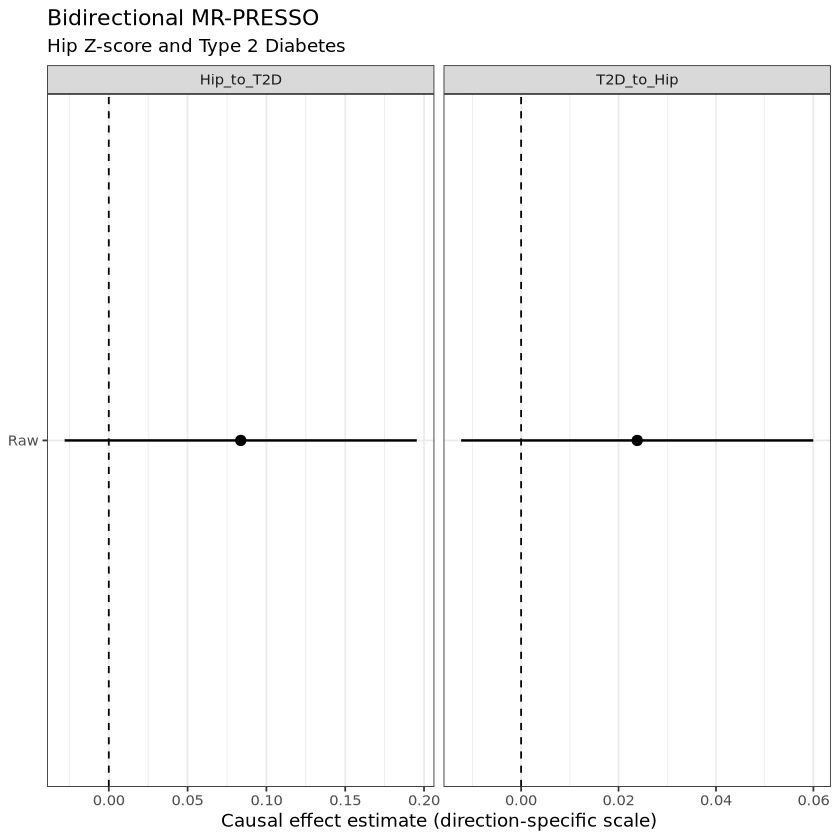

In [6]:
# ============================================================
# 5. MR-PRESSO Results and Figures
# ============================================================

# ============================================================
# 5.1 Prepare causal effect estimates
# ============================================================

raw_results <- presso_results[
  ,
  .(
    Direction,
    Analysis = "Raw",
    Beta = Raw_Beta,
    SE = Raw_SE,
    P = Raw_P
  )
]

corrected_results <- presso_results[
  ,
  .(
    Direction,
    Analysis = "Outlier-corrected",
    Beta = Corrected_Beta,
    SE = Corrected_SE,
    P = Corrected_P
  )
]

estimate_table <- rbindlist(
  list(
    raw_results,
    corrected_results
  )
)

estimate_table <- estimate_table[
  is.finite(Beta) &
  is.finite(SE) &
  SE > 0
]

estimate_table[
  ,
  CI_Lower := Beta - 1.96 * SE
]

estimate_table[
  ,
  CI_Upper := Beta + 1.96 * SE
]

# T2D outcome: convert log-odds effects to OR.
estimate_table[, OR := NA_real_]
estimate_table[, OR_Lower := NA_real_]
estimate_table[, OR_Upper := NA_real_]

estimate_table[
  Direction == "Hip_to_T2D",
  `:=`(
    OR = exp(Beta),
    OR_Lower = exp(CI_Lower),
    OR_Upper = exp(CI_Upper)
  )
]

fwrite(
  estimate_table,
  file.path(OUT_DIR, "MR_PRESSO_Estimates.csv")
)

cat("\n===== MR-PRESSO ESTIMATES =====\n")
print(estimate_table)

# ============================================================
# 5.2 Forest plot
# ============================================================

if (nrow(estimate_table) > 0) {

  estimate_table[, Analysis := factor(
    Analysis,
    levels = c("Raw", "Outlier-corrected")
  )]

  p <- ggplot(
    estimate_table,
    aes(x = Beta, y = Analysis)
  ) +
    geom_segment(
      aes(
        x = CI_Lower,
        xend = CI_Upper,
        yend = Analysis
      ),
      linewidth = 0.7
    ) +
    geom_point(size = 2.5) +
    geom_vline(
      xintercept = 0,
      linetype = "dashed"
    ) +
    facet_wrap(
      ~Direction,
      scales = "free_x"
    ) +
    labs(
      title = "Bidirectional MR-PRESSO",
      subtitle = "Hip Z-score and Type 2 Diabetes",
      x = "Causal effect estimate (direction-specific scale)",
      y = NULL
    ) +
    theme_bw()

  print(p)

  ggsave(
    filename = file.path(
      OUT_DIR, "MR_PRESSO_Forest.png"
    ),
    plot = p,
    width = 10,
    height = 5,
    dpi = 200
  )
}

# ============================================================
# 5.3 Save analysis parameters
# ============================================================

parameters <- data.table(
  Parameter = c(
    "IV_P_Threshold",
    "Clump_P1",
    "Clump_P2",
    "Clump_R2",
    "Clump_KB",
    "Outcome_P_Exclusion",
    "Minimum_F_Statistic",
    "Harmonization_Action",
    "MRPRESSO_NbDistribution",
    "Original_Study_NbDistribution",
    "MRPRESSO_SignifThreshold",
    "Random_Seed"
  ),
  Value = as.character(c(
    IV_P_THRESHOLD,
    CLUMP_P1,
    CLUMP_P2,
    CLUMP_R2,
    CLUMP_KB,
    OUTCOME_P_EXCLUSION,
    MIN_F_STATISTIC,
    HARMONISE_ACTION,
    MR_PRESSO_NB_DISTRIBUTION,
    25000,
    MR_PRESSO_SIGNIF_THRESHOLD,
    RANDOM_SEED
  ))
)

fwrite(
  parameters,
  file.path(OUT_DIR, "MR_Parameters.csv")
)

# ============================================================
# 5.4 Save software information
# ============================================================

writeLines(
  capture.output(sessionInfo()),
  file.path(OUT_DIR, "MR_SessionInfo.txt")
)

# ============================================================
# 5.5 Final execution summary
# ============================================================

cat("\n========================================\n")
cat("STEP 8 — MR-PRESSO FINISHED\n")
cat("========================================\n")

print(iv_summary)
print(presso_results)

cat("\nGenerated summary files:\n")

print(
  basename(
    list.files(
      OUT_DIR,
      full.names = TRUE
    )
  )
)